In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/cleaned/books_cleaned.csv")

df.head()

,UPC,Product Type,Price (excl. tax),Price (incl. tax),Tax,Availability,Number of reviews,BookTitle,BookDescription,BookRating,ProductURL,BookCategory,StockQuantity
0,a22124811bfa8350,Books,45.17,45.17,0.0,In stock (19 available),0,It's Only the Himalayas,"“Wherever you go, whatever you do, just . . . ...",2,https://books.toscrape.com/catalogue/its-only-...,Travel,19
1,ce60436f52c5ee68,Books,49.43,49.43,0.0,In stock (15 available),0,Full Moon over Noah’s Ark: An Odyssey to Mount...,Acclaimed travel writer Rick Antonson sets his...,4,https://books.toscrape.com/catalogue/full-moon...,Travel,15
2,f9705c362f070608,Books,48.87,48.87,0.0,In stock (14 available),0,See America: A Celebration of Our National Par...,To coincide with the 2016 centennial anniversa...,3,https://books.toscrape.com/catalogue/see-ameri...,Travel,14
3,1809259a5a5f1d8d,Books,36.94,36.94,0.0,In stock (8 available),0,Vagabonding: An Uncommon Guide to the Art of L...,With a new foreword by Tim Ferriss •There’s no...,2,https://books.toscrape.com/catalogue/vagabondi...,Travel,8
4,a94350ee74deaa07,Books,37.33,37.33,0.0,In stock (7 available),0,Under the Tuscan Sun,A CLASSIC FROM THE BESTSELLING AUTHOR OF UNDER...,3,https://books.toscrape.com/catalogue/under-the...,Travel,7


In [3]:
df.shape

(163, 13)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 163 entries, 0 to 162
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   UPC                163 non-null    str    
 1   Product Type       163 non-null    str    
 2   Price (excl. tax)  163 non-null    float64
 3   Price (incl. tax)  163 non-null    float64
 4   Tax                163 non-null    float64
 5   Availability       163 non-null    str    
 6   Number of reviews  163 non-null    int64  
 7   BookTitle          163 non-null    str    
 8   BookDescription    162 non-null    str    
 9   BookRating         163 non-null    int64  
 10  ProductURL         163 non-null    str    
 11  BookCategory       163 non-null    str    
 12  StockQuantity      163 non-null    int64  
dtypes: float64(3), int64(3), str(7)
memory usage: 16.7 KB


In [5]:
df.isnull().sum()

UPC                  0
Product Type         0
Price (excl. tax)    0
Price (incl. tax)    0
Tax                  0
Availability         0
Number of reviews    0
BookTitle            0
BookDescription      1
BookRating           0
ProductURL           0
BookCategory         0
StockQuantity        0
dtype: int64

In [6]:
df["BookCategory"].value_counts()

BookCategory
Sequential Art        75
Mystery               32
Historical Fiction    26
Classics              19
Travel                11
Name: count, dtype: int64

In [7]:
df[[
    "Price (excl. tax)",
    "BookRating",
    "StockQuantity",
    "Number of reviews"
]].describe()

,Price (excl. tax),BookRating,StockQuantity,Number of reviews
count,163.000000,163.000000,163.000000,163.0
mean,34.446503,2.932515,8.061350,0.0
std,14.216473,1.347741,6.120894,0.0
min,10.160000,1.000000,1.000000,0.0
25%,21.320000,2.000000,3.000000,0.0
50%,35.280000,3.000000,6.000000,0.0
75%,46.935000,4.000000,14.000000,0.0
max,59.480000,5.000000,20.000000,0.0


<function matplotlib.pyplot.show(close=None, block=None)>

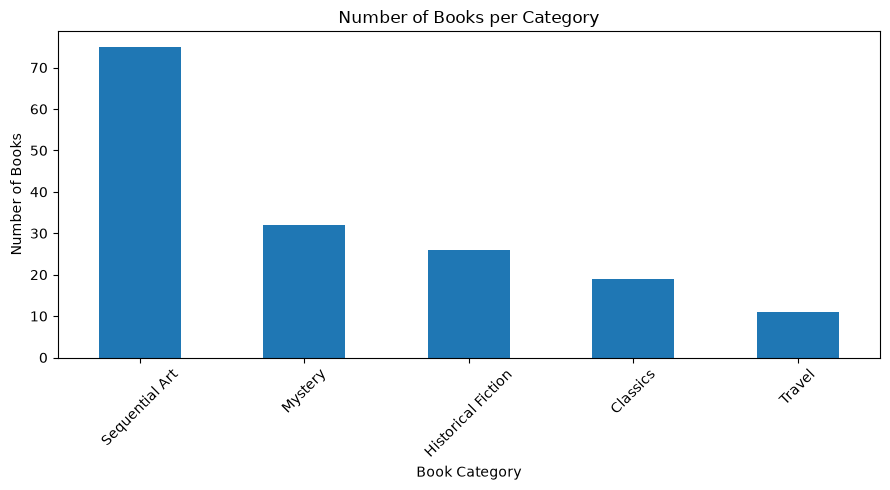

In [12]:
category_counts = df["BookCategory"].value_counts()

category_counts.plot(kind="bar", figsize=(9, 5))

plt.title("Number of Books per Category")
plt.xlabel("Book Category")
plt.ylabel("Number of Books")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../visualizations/books-by-category.png", dpi=300)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

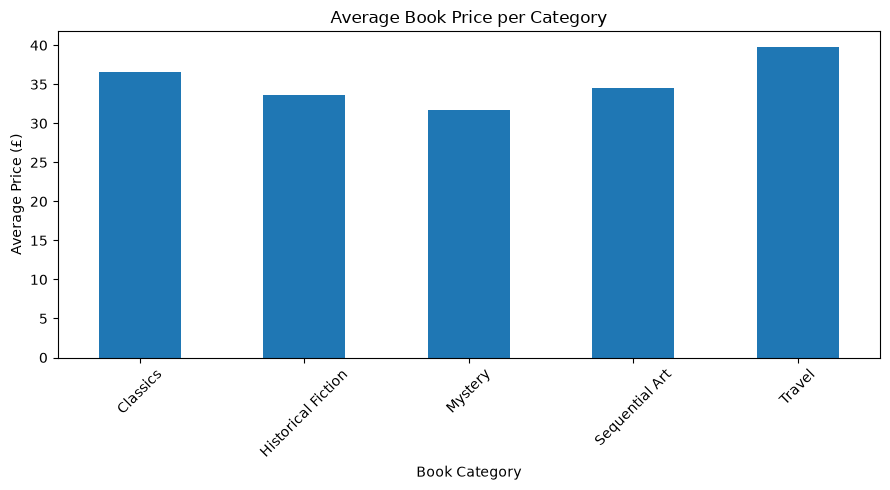

In [13]:
average_prices = df.groupby("BookCategory")["Price (excl. tax)"].mean()
average_prices.plot(kind="bar", figsize=(9, 5))

plt.title("Average Book Price per Category")
plt.xlabel("Book Category")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../visualizations/average-price-by-category.png", dpi=300)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

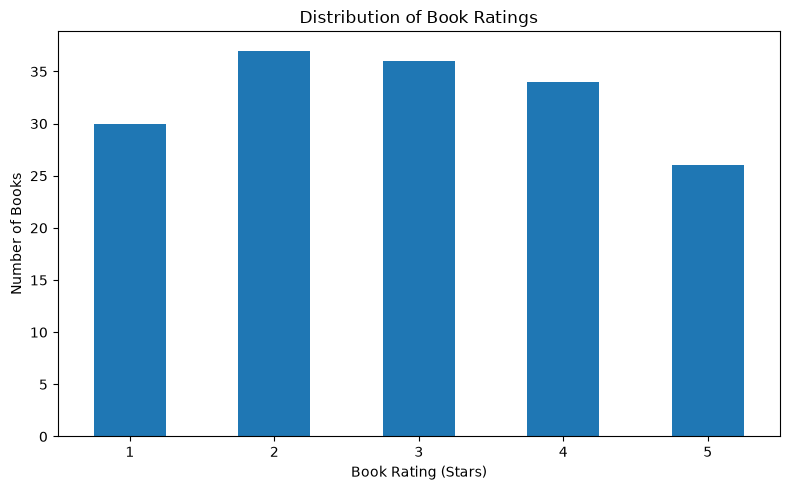

In [14]:
rating_counts = df["BookRating"].value_counts().sort_index()
rating_counts.plot(kind="bar", figsize=(8, 5))

plt.title("Distribution of Book Ratings")
plt.xlabel("Book Rating (Stars)")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../visualizations/book-rating-distribution.png", dpi=300)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

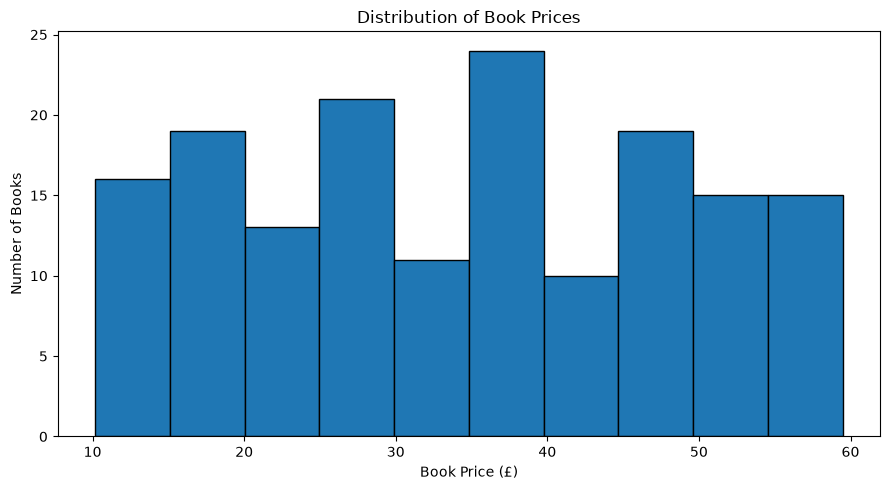

In [16]:
plt.figure(figsize=(9, 5))
plt.hist(df["Price (excl. tax)"], edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Book Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.savefig("../visualizations/book-price-distribution.png", dpi=300)
plt.show

In [19]:
category_summary = df.groupby("BookCategory").agg(
    Total_Books=("BookTitle", "count"),
    Average_price=("Price (excl. tax)", "mean"),
    Average_Rating=("BookRating", "mean"),
    Total_Stock=("StockQuantity", "sum")                              
)

category_summary

,Total_Books,Average_price,Average_Rating,Total_Stock
BookCategory,,,,
Classics,19,36.545263,2.473684,55
Historical Fiction,26,33.644231,3.230769,194
Mystery,32,31.719062,2.937500,290
Sequential Art,75,34.572267,2.973333,686
Travel,11,39.794545,2.727273,89


<function matplotlib.pyplot.show(close=None, block=None)>

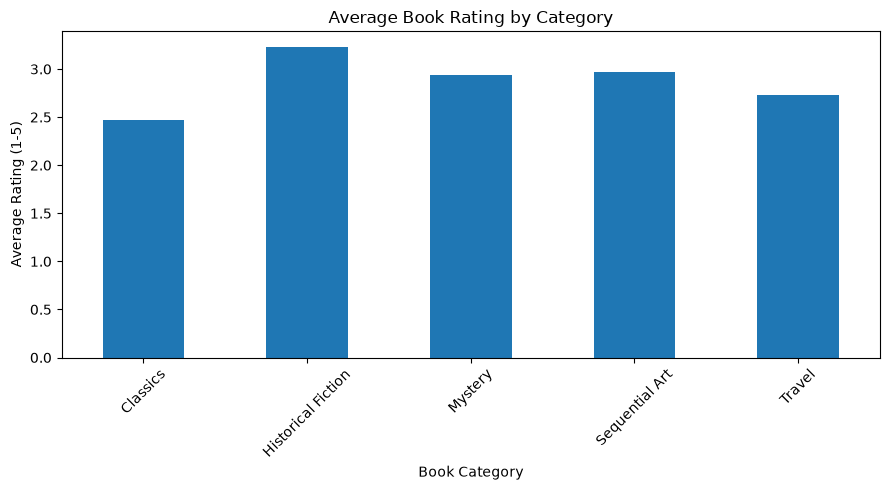

In [20]:
category_summary["Average_Rating"].plot(kind="bar", figsize=(9, 5))

plt.title("Average Book Rating by Category")
plt.xlabel("Book Category")
plt.ylabel("Average Rating (1-5)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../visualizations/average-rating-by-category.png", dpi=300)
plt.show

In [21]:
most_expensive_books = df.nlargest(5, "Price (excl. tax)")
most_expensive_books[["BookTitle", "BookCategory", "Price (excl. tax)", "BookRating"]]

,BookTitle,BookCategory,Price (excl. tax),BookRating
25,Boar Island (Anna Pigeon #19),Mystery,59.48,3
150,Candide,Classics,58.63,3
38,The No. 1 Ladies' Detective Agency (No. 1 Ladi...,Mystery,57.70,4
103,El Deafo,Sequential Art,57.62,5
151,Animal Farm,Classics,57.22,3


In [22]:
cheapest_books = df.nsmallest(5, "Price (excl. tax)")
cheapest_books[["BookTitle", "BookCategory", "Price (excl. tax)", "BookRating"]]

,BookTitle,BookCategory,Price (excl. tax),BookRating
77,Patience,Sequential Art,10.16,3
132,The Complete Maus (Maus #1-2),Sequential Art,10.64,3
18,Tastes Like Fear (DI Marnie Rome #3),Mystery,10.69,1
106,"Adulthood Is a Myth: A ""Sarah's Scribbles"" Col...",Sequential Art,10.90,2
128,"Fruits Basket, Vol. 2 (Fruits Basket #2)",Sequential Art,11.64,5
